In [1]:
import bw2data as bd
import bw2io as bi
import bw2calc as bc
import bw2analyzer as bwa
import plotly
import polars as pl 
from tqdm import tqdm

bd.projects.set_current("2026-01-13-ecoinvent-3.11-cutoff")

08:43:13+0100 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


In [2]:
gwps = [m for m in bd.methods if "gwp" in str(m).lower() and "no LT" not in str(m) and "EF v3.1" in str(m) and "fossil" not in str(m) and "biogenic" not in str(m) and "land" not in str(m)]
gwps

[('ecoinvent-3.11',
  'EF v3.1',
  'climate change',
  'global warming potential (GWP100)'),
 ('ecoinvent-3.11',
  'EN15804+A2 - Core impact categories and indicators',
  'climate change: total (EF v3.1 - IPCC 2021)',
  'global warming potential (GWP100)')]

In [3]:
from archetypes_re2020.archetypes.buildings_based_archetypes_db import load_parquet_data, INPUT_PATH
from archetypes_re2020.data.source import INPUT_PATHS

df_buildings = pl.read_csv(
    source=INPUT_PATHS["BUILDINGS"], ignore_errors=True
    )

In [7]:
build_db = bd.Database('2026-3-23-14h21_buildings_RE2020')

In [ ]:
build_db.random().as_dict()

In [5]:
prodb = bd.Database('2026-3-19-11h18_processes_RE2020')

In [ ]:
s = set([b['usage'] for b in build_db if b['usage'] is not None])

In [ ]:
p = set([prod for prod in prodb])

In [ ]:
from itertools import product
res = { k : 0 for k in product(s,p)}

In [14]:
def total_area_per_use(df) :
    
    usages = df.select(
        pl.col("usage_principal_1_txt").unique()
        ).drop_nulls()["usage_principal_1_txt"]


    return {
        u : df.filter(
            pl.col("usage_principal_1_txt")==u
            ).select("projet_id","batiment_index","sref").unique()["sref"].sum()
            for u in usages
            }

areas_per_use = total_area_per_use(df_buildings)

In [ ]:
for b in tqdm(build_db) :
    usage = b["usage"]
    
    if usage is None :
        continue
    else :
        sref = list(b.consumers())[0].amount
        for e in list(b.technosphere()) :
            res[(usage,e.input)]+=e.amount*sref

In [ ]:
from datetime import datetime

today = datetime.today()

import pickle

with open(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/{today.year}-{today.month}-{today.day}_amounts_procedes_par_arch_pr_sankey.pkl", "wb") as f:
    pickle.dump(res, f)

In [ ]:
import pickle
with open("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/2026-3-23_amounts_procedes_par_arch_pr_sankey.pkl", "rb") as f:
    res = pickle.load(f)

In [ ]:
import pickle
with open("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/2026-3-23_amounts_procedes_par_arch.pkl", "rb") as f:
    res = pickle.load(f)

In [ ]:
del bd.databases["pr_based_arch_alamain"]

In [4]:
arch_db = bd.Database("pr_based_arch_alamain")

In [ ]:
list(res_str_keys.keys())

In [ ]:
keys = []
values = []

for usage in tqdm(s) : 
    archetype_code = str(usage).lower().replace(' ',"_")
    archetypes_db_name = arch_db.name
    key = (archetypes_db_name, archetype_code)
    keys.append(key)
    
    ref_amount = areas_per_use[usage]

    ref_flow = {
        'input': key,
        'amount': ref_amount,
        'type': 'production',
        'output': key
    }

    prodb_name =prodb.name

    techno_flows = [
        {
                'input': (prodb_name,p["code"]),
                'amount': res[(usage,p)],
                'type': 'technosphere',
                'output': key
            }
            for p in prodb
    
    ]

    value = {
        "name" : str(usage).replace(' ',"_"),
        "unit" : 'm2',
        "location" : "FR",
        "exchanges" : [ref_flow]+techno_flows
        }
    values.append(value)


nodes = {keys[i] : values[i] for i in range(len(keys))}


In [ ]:
nodes

In [ ]:
arch_db.write(nodes)

In [ ]:
a = arch_db.random()

In [ ]:
a

In [ ]:
lca= bc.LCA(demand={a:1.0}, method=gwps[1])
lca.lci()
lca.lcia()
score = lca.score

In [ ]:
from bw_graph_tools import NewNodeEachVisitGraphTraversal
from bw2analyzer import GTManipulator

# Run graph traversal — pass the LCA object, not the demand dict
gt_result = NewNodeEachVisitGraphTraversal.calculate(
    lca_object=lca,
    cutoff=0.01,
    max_calc=100000
)

nodes = gt_result["nodes"]
edges = gt_result["edges"]

In [ ]:
import plotly.graph_objects as go
method = gwps[1]

# ── 3. Build label lookup using activity_index (matrix row → bw2data key) ─────
# lca.dicts.activity maps bw2data integer id → matrix row index
# We reverse it: matrix row index → bw2data integer id
reverse_activity = {v: k for k, v in lca.dicts.activity.items()}

def get_label(node):
    if node.activity_index < 0:
        return a["name"] + " [ROOT]"
    try:
        bw2data_id = reverse_activity.get(node.activity_index)
        if bw2data_id is not None:
            act = bd.get_activity(bw2data_id)
            name = act.get("name", "?")
            loc  = act.get("location", "")
            return f"{name} [{loc}]" if loc else name
    except Exception:
        pass
    return f"node_{node.unique_id}"

# ── 4. Build node list and index ──────────────────────────────────────────────
node_list  = list(nodes.values())
uid_to_idx = {n.unique_id: i for i, n in enumerate(node_list)}
uid_to_node = {n.unique_id: n for n in node_list}

node_labels = [get_label(n) for n in node_list]
node_scores = [n.cumulative_score for n in node_list]

# ── 5. Build edges — use producer cumulative_score as the flow value ──────────
sources, targets, values = [], [], []

for edge in edges:
    src = uid_to_idx.get(edge.consumer_unique_id)
    tgt = uid_to_idx.get(edge.producer_unique_id)

    # Use the producer node's cumulative_score as flow magnitude
    producer_node = uid_to_node.get(edge.producer_unique_id)
    val = abs(producer_node.cumulative_score) if producer_node else 0

    if src is not None and tgt is not None and val > 0:
        sources.append(src)
        targets.append(tgt)
        values.append(val)

# ── 6. Plot ───────────────────────────────────────────────────────────────────
# Color nodes by share of total score
import plotly.colors as pc

def score_to_color(s, total):
    share = min(abs(s) / abs(total), 1.0)
    # Blue (low) → Red (high)
    r = int(255 * share)
    b = int(255 * (1 - share))
    return f"rgba({r}, 80, {b}, 0.85)"

node_colors = [score_to_color(n.cumulative_score, score) for n in node_list]

fig = go.Figure(data=[go.Sankey(
    arrangement="snap",
    node=dict(
        pad=20,
        thickness=20,
        label=node_labels,
        color=node_colors,
        hovertemplate=(
            "<b>%{label}</b><br>"
            "Cumulative score: %{customdata:.4g}<extra></extra>"
        ),
        customdata=node_scores,
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color="rgba(180,180,180,0.4)",
    ),
)])

fig.update_layout(
    title=dict(
        text=f"Supply chain — {a['name']}<br>"
             f"<sup>Total score: {score:.4g} | Method: {method[-1]}</sup>",
        font_size=14,
    ),
    font_size=11,
    height=700,
)

fig.show()

In [ ]:
bd.methods

In [15]:


demands = { f"{a}" : {a.id : 1.0 } for a in arch_db}
# demands = { f"{a}" : {a.id : 1.0 } for a in [delta]}
config = {"impact_categories" : [gwps[1]]}

data_objs = bd.get_multilca_data_objs(functional_units=demands
                                      ,method_config=config)

n_MC = 1000

import time
start = time.time()
mlca = bc.MultiLCA(
    demands=demands
    ,method_config=config
    ,data_objs=data_objs
    ,use_distributions= True
    # ,selective_use = {
    #     "technosphere_matrix" : {"use_distributions" : False}
    #     ,"biosphere_matrix" : {"use_distributions" : False}
    #     ,"characterization_matrix" : {"use_distributions" : False}
    #     }
    )

mlca.lci()
mlca.lcia()

In [16]:
lca_all = [mlca.scores for _ in tqdm(zip(mlca,range(n_MC)))]

1000it [14:57,  1.11it/s]


In [17]:
import pickle
from datetime import datetime

today = datetime.today()

with open(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/{today.year}-{today.month}-{today.day}_MC_pr_based_arch_gwp_EN15804.pkl", "wb") as f:
    pickle.dump(lca_all, f)

In [19]:
import polars as pl
import simplstyles
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("nord-light")

In [23]:
lca_all[999]

{(('ecoinvent-3.11',
   'EN15804+A2 - Core impact categories and indicators',
   'climate change: total (EF v3.1 - IPCC 2021)',
   'global warming potential (GWP100)'),
  "'Enseignement_secondaire_(partie_jour)' (m2, FR, None)"): 992.2903888308729,
 (('ecoinvent-3.11',
   'EN15804+A2 - Core impact categories and indicators',
   'climate change: total (EF v3.1 - IPCC 2021)',
   'global warming potential (GWP100)'),
  "'Bureau' (m2, FR, None)"): 1147.1999376186634,
 (('ecoinvent-3.11',
   'EN15804+A2 - Core impact categories and indicators',
   'climate change: total (EF v3.1 - IPCC 2021)',
   'global warming potential (GWP100)'),
  "'Enseignement_primaire' (m2, FR, None)"): 1184.9427763431643,
 (('ecoinvent-3.11',
   'EN15804+A2 - Core impact categories and indicators',
   'climate change: total (EF v3.1 - IPCC 2021)',
   'global warming potential (GWP100)'),
  "'Maison_individuelle_ou_accolée' (m2, FR, None)"): 1029.8408388319656,
 (('ecoinvent-3.11',
   'EN15804+A2 - Core impact categ

In [32]:
to_graph = pl.DataFrame(schema={"usage" : pl.String,"score" : pl.Float64,"indicateur" : pl.String})

for d in lca_all:
    for t,s in d.items():
        print(t[0])
        new_row = pl.DataFrame(
            {
                "usage": t[1],
                "score" : s,
                "indicateur" : str(t[0]),
            }
            )
        to_graph.extend(new_row)


('ecoinvent-3.11', 'EN15804+A2 - Core impact categories and indicators', 'climate change: total (EF v3.1 - IPCC 2021)', 'global warming potential (GWP100)')
('ecoinvent-3.11', 'EN15804+A2 - Core impact categories and indicators', 'climate change: total (EF v3.1 - IPCC 2021)', 'global warming potential (GWP100)')
('ecoinvent-3.11', 'EN15804+A2 - Core impact categories and indicators', 'climate change: total (EF v3.1 - IPCC 2021)', 'global warming potential (GWP100)')
('ecoinvent-3.11', 'EN15804+A2 - Core impact categories and indicators', 'climate change: total (EF v3.1 - IPCC 2021)', 'global warming potential (GWP100)')
('ecoinvent-3.11', 'EN15804+A2 - Core impact categories and indicators', 'climate change: total (EF v3.1 - IPCC 2021)', 'global warming potential (GWP100)')
('ecoinvent-3.11', 'EN15804+A2 - Core impact categories and indicators', 'climate change: total (EF v3.1 - IPCC 2021)', 'global warming potential (GWP100)')
('ecoinvent-3.11', 'EN15804+A2 - Core impact categories an

In [33]:
to_graph

usage,score,indicateur
str,f64,str
"""'Enseignement_secondaire_(part…",807.408008,"""('ecoinvent-3.11', 'EN15804+A2…"
"""'Bureau' (m2, FR, None)""",981.543477,"""('ecoinvent-3.11', 'EN15804+A2…"
"""'Enseignement_primaire' (m2, F…",923.361695,"""('ecoinvent-3.11', 'EN15804+A2…"
"""'Maison_individuelle_ou_accolé…",877.376407,"""('ecoinvent-3.11', 'EN15804+A2…"
"""'Logement_collectif' (m2, FR, …",959.201328,"""('ecoinvent-3.11', 'EN15804+A2…"
…,…,…
"""'Enseignement_secondaire_(part…",992.290389,"""('ecoinvent-3.11', 'EN15804+A2…"
"""'Bureau' (m2, FR, None)""",1147.199938,"""('ecoinvent-3.11', 'EN15804+A2…"
"""'Enseignement_primaire' (m2, F…",1184.942776,"""('ecoinvent-3.11', 'EN15804+A2…"


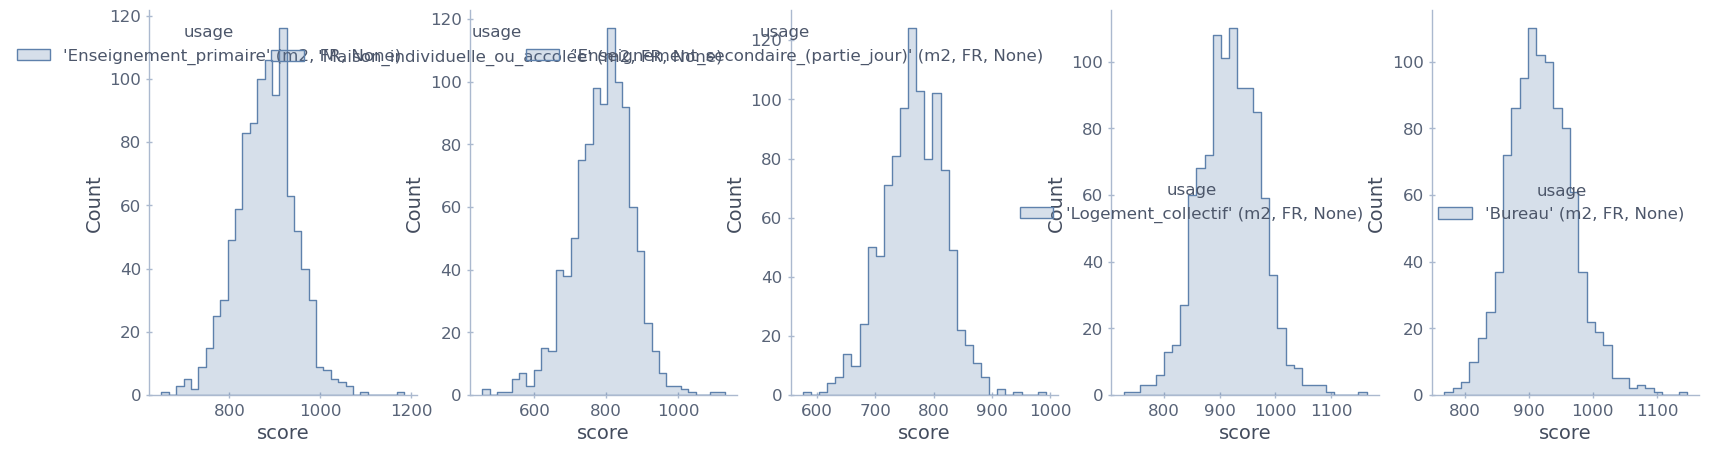

In [37]:
fig, ax = plt.subplots(1,5,figsize = (20,5))
i = 0
for usage in  to_graph["usage"].unique() : 
    sns.histplot(data=to_graph.filter(pl.col("usage") == usage), x = "score",hue="usage",element="step",ax=ax[i])
    i+=1

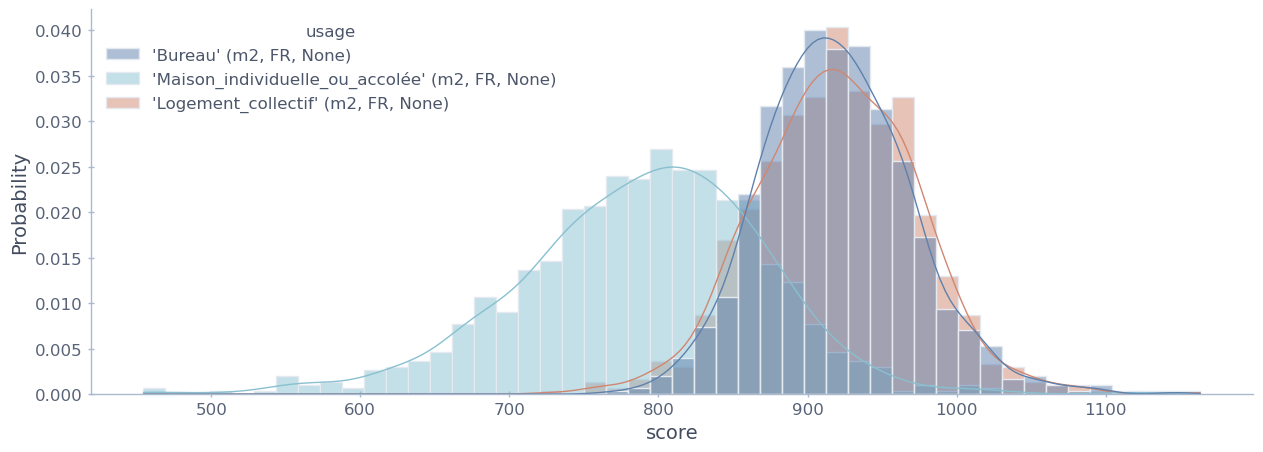

In [60]:
plt.style.use("nord-light")
fig, ax = plt.subplots(figsize = (15,5))
sns.histplot(
    data=to_graph.filter(~pl.col("usage").str.contains("Enseignement")), 
    x = "score",
    # x="usage",
    hue="usage",
    kde = True,
    stat="probability"
    )
title = "MC_gwp100_EN15804_1000"
plt.savefig(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/{today.year}-{today.month}-{today.day}_{title}.pdf",dpi = 300)

In [62]:

import numpy as np
stats = {u:{} for u in to_graph["usage"].unique()}
for u in to_graph["usage"].unique():
    tmp = list(to_graph.filter(pl.col("usage")==u)["score"])
    stats[u]["median"] = np.median(tmp)
    stats[u]["mean"] = np.mean(tmp)
    stats[u]["std"] = np.std(tmp)
    stats[u]["min"] = np.min(tmp)
    stats[u]["max"] = np.max(tmp)


In [63]:
stats

{"'Enseignement_primaire' (m2, FR, None)": {'median': 883.0206007396586,
  'mean': 880.6078977030368,
  'std': 63.588647395438464,
  'min': 650.6636150983913,
  'max': 1184.9427763431643},
 "'Logement_collectif' (m2, FR, None)": {'median': 918.9142054829424,
  'mean': 919.5151010361907,
  'std': 53.77341760328884,
  'min': 727.8490433240885,
  'max': 1163.445416115827},
 "'Bureau' (m2, FR, None)": {'median': 917.0164916420213,
  'mean': 919.4665862300797,
  'std': 49.67605881709681,
  'min': 768.0631439248124,
  'max': 1147.1999376186634},
 "'Enseignement_secondaire_(partie_jour)' (m2, FR, None)": {'median': 766.544944318098,
  'mean': 765.9493680751009,
  'std': 51.4507323417326,
  'min': 575.4158930636007,
  'max': 992.2903888308729},
 "'Maison_individuelle_ou_accolée' (m2, FR, None)": {'median': 795.7206546608631,
  'mean': 789.5437147233619,
  'std': 81.96209989956209,
  'min': 454.5718168853027,
  'max': 1130.8491274455898}}

In [4]:
bd.databases

Databases dictionary with 20 object(s):
	2026-2-12-10h51_bernoulli_RE2020
	2026-3-13-17h6_processes_RE2020
	2026-3-18-14h25_archetypes_RE2020_BB
	2026-3-18-14h52_buildings_RE2020
	2026-3-19-11h18_processes_RE2020
	2026-3-19-11h27_buildings_RE2020
	2026-3-19-13h44_archetypes_RE2020_BB
	2026-3-23-10h43_archetypes_RE2020_BB
	2026-3-23-11h32_buildings_RE2020
	2026-3-23-14h21_buildings_RE2020
	2026-3-23-14h9_archetypes_RE2020_BB
	2026-3-23-15h9_archetypes_RE2020_BB
	ciogen_custom
	ciogen_fin_de_vie
	ciogen_ponts_production
	ciogen_production
	ciogen_transport
	ecoinvent-3.11-biosphere
	ecoinvent-3.11-cutoff
	pr_based_arch_alamain

In [5]:
prod_db = bd.Database("2026-3-19-11h18_processes_RE2020")
build_db = bd.Database('2026-3-23-14h21_buildings_RE2020')

In [9]:
demands = { f"{p["code"]}" : {p.id : 1.0 } for p in prod_db}
# demands = { f"{a}" : {a.id : 1.0 } for a in [delta]}
config = {"impact_categories" : [gwps[1]]}

data_objs = bd.get_multilca_data_objs(functional_units=demands
                                      ,method_config=config)

n_MC = 800

import time
start = time.time()
mlca = bc.MultiLCA(
    demands=demands
    ,method_config=config
    ,data_objs=data_objs
    ,use_distributions= True
    # ,selective_use = {
    #     "technosphere_matrix" : {"use_distributions" : False}
    #     ,"biosphere_matrix" : {"use_distributions" : False}
    #     ,"characterization_matrix" : {"use_distributions" : False}
    #     }
    )

mlca.lci()
mlca.lcia()

In [10]:
lca_all = [mlca.scores for _ in tqdm(zip(mlca,range(n_MC)))]

800it [1:20:44,  6.06s/it]


In [11]:
import pickle
from datetime import datetime

today = datetime.today()

with open(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/{today.year}-{today.month}-{today.day}_MC_products_gwp_EN15804_800.pkl", "wb") as f:
    pickle.dump(lca_all, f)

In [21]:
list(lca_all[0].keys())[0][1]

'isolation thermique et acoustique des tuyaux/conduits/équipements_traitement acoustique_unité_30'

In [18]:
type(gwps[1])

tuple

In [24]:
res_pro = {p["code"] : [d[(gwps[1],p["code"])] for d in lca_all] for p in tqdm(prod_db)}

100%|██████████| 367/367 [00:00<00:00, 1897.70it/s]


In [26]:
from random import randint
res_build = {b["code"] : [] for b in build_db}
n_MC_build = 500
for b in tqdm(build_db) :
    dict_exch ={bd.get_node(database = e.input["database"], code= e.input["code"])["code"] : e.amount for e in b.technosphere()}
    for _ in range(n_MC_build) :
        i = randint(0,n_MC-1)
        tmp = [res_pro[p][i]*amount for p,amount in dict_exch.items()]
        res_build[b["code"]].append(sum(tmp))


100%|██████████| 79644/79644 [50:18<00:00, 26.39it/s]  


In [27]:
import pickle
from datetime import datetime

today = datetime.today()

with open(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/{today.year}-{today.month}-{today.day}_MC_buildings_gwp_EN15804_500.pkl", "wb") as f:
    pickle.dump(res_build, f)

In [4]:
import pickle

with open(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/2026-3-24_MC_buildings_gwp_EN15804_500.pkl", "rb") as f:
   res_build= pickle.load(f)

In [8]:
usages = set([b["usage"] for b in build_db if b["usage"] is not None])

In [9]:
usages

{'Bureau',
 'Enseignement primaire',
 'Enseignement secondaire (partie jour)',
 'Logement collectif',
 'Maison individuelle ou accolée'}

In [11]:
dict_build_use = {u : {b["code"]: list(b.consumers())[0].amount for b in build_db if b["usage"]==u} for u in tqdm(usages)}

100%|██████████| 5/5 [00:53<00:00, 10.71s/it]


In [ ]:
res_arch = {u : [] for u in usages}

for u in tqdm(usages) :
    stot = areas_per_use[u]
    d_codes = dict_build_use[u]
    for code,sref in tqdm(d_codes.items()) :
        res_arch[u] = res_arch[u] + [s*sref for s in res_build[code]]
    
    res_arch[u] = [s/stot for s in res_arch[u]]

NameError: name 'usages' is not defined

In [ ]:
import pickle
from datetime import datetime

today = datetime.today()

with open(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/{today.year}-{today.month}-{today.day}_MC_arch_gwp_EN15804_500.pkl", "wb") as f:
    pickle.dump(res_arch, f)

In [12]:
sum_areas = { u: sum([v for v in dict_build_use[u].values()]) for u in usages}

In [13]:
sum_areas

{'Bureau': 582465.9,
 'Logement collectif': 1329599.4,
 'Maison individuelle ou accolée': 8400401.2,
 'Enseignement secondaire (partie jour)': 45899.3,
 'Enseignement primaire': 41927.8}

In [14]:
import numpy as np
n_MC_arch = 1000

d_prob_per_use= { u: { k : v/sum_areas[u] for k,v in dict_build_use[u].items()} for u in usages}

d_tirages ={u : [] for u in usages}
for u in tqdm(d_tirages.keys()):
    d_probas = d_prob_per_use[u]
    elements=list(d_probas.keys())
    probas=list(d_probas.values())

    # print(sum(probas))
    d_tirages[u]=[np.random.choice(elements,p=probas) for _ in range(n_MC_arch)]



100%|██████████| 5/5 [00:14<00:00,  2.88s/it]


In [15]:
res_arch = {u : [] for u in usages}

for u in tqdm(res_arch.keys()) : 
    for b_code in d_tirages[u] : 
        res_arch[u] = res_arch[u] + res_build[b_code]

100%|██████████| 5/5 [00:04<00:00,  1.09it/s]


In [16]:
to_graph = pl.DataFrame(res_arch)

In [17]:
from archetypes_re2020.data.remove_extreme_outliers import outliers

In [18]:
to_graph = outliers(to_graph.melt(variable_name="usage",value_name="score"),"score")
to_graph

/tmp/ipykernel_13729/1140440709.py:1: DeprecationWarning: `DataFrame.melt` is deprecated; use `DataFrame.unpivot` instead, with `index` instead of `id_vars` and `on` instead of `value_vars`
  to_graph = outliers(to_graph.melt(variable_name="usage",value_name="score"),"score")


usage,score,mild_outliers,extreme_outliers
str,f64,bool,bool
"""Bureau""",700.693432,false,false
"""Bureau""",767.181189,false,false
"""Bureau""",954.891064,false,false
"""Bureau""",695.15507,false,false
"""Bureau""",802.054142,false,false
…,…,…,…
"""Enseignement primaire""",678.676716,false,false
"""Enseignement primaire""",658.787466,false,false
"""Enseignement primaire""",658.507419,false,false


In [19]:
to_graph.filter(pl.col("extreme_outliers") == False,pl.col("mild_outliers") == False,)

usage,score,mild_outliers,extreme_outliers
str,f64,bool,bool
"""Bureau""",700.693432,false,false
"""Bureau""",767.181189,false,false
"""Bureau""",954.891064,false,false
"""Bureau""",695.15507,false,false
"""Bureau""",802.054142,false,false
…,…,…,…
"""Enseignement primaire""",678.676716,false,false
"""Enseignement primaire""",658.787466,false,false
"""Enseignement primaire""",658.507419,false,false


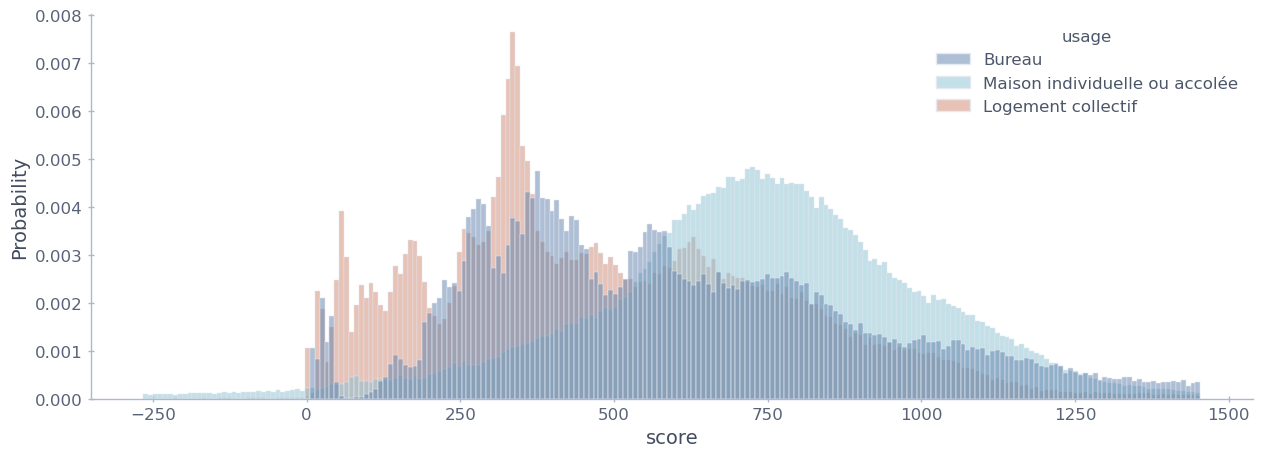

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import simplstyles
from datetime import datetime

today = datetime.today()

plt.style.use("nord-light")
fig, ax = plt.subplots(figsize = (15,5))
sns.histplot(
    data=to_graph.filter(
        ~pl.col("usage").str.contains("Enseignement"),
        pl.col("extreme_outliers") == False,
        pl.col("mild_outliers") == False,
        ), 
    x = "score",
    # x="usage",
    hue="usage",
    hue_order = ["Bureau", "Maison individuelle ou accolée", "Logement collectif"],
    # kde = True,
    stat="probability"
    )
title = "MC_arch_gwp100_EN15804_1000"
plt.savefig(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/{today.year}-{today.month}-{today.day}_{title}.pdf",dpi = 300)

In [63]:
import numpy as np
stats = {u:{} for u in to_graph["usage"].unique()}
for u in to_graph["usage"].unique():
    tmp = list(to_graph.filter(pl.col("usage")==u)["score"])
    stats[u]["median"] = np.median(tmp)
    stats[u]["mean"] = np.mean(tmp)
    stats[u]["std"] = np.std(tmp)
    stats[u]["min"] = np.min(tmp)
    stats[u]["max"] = np.max(tmp)


In [64]:
stats

{'Maison individuelle ou accolée': {'median': 739.2463972749003,
  'mean': 682.4037106055016,
  'std': 1172.285491065652,
  'min': -86049.16119042503,
  'max': 4371.724622895399},
 'Enseignement secondaire (partie jour)': {'median': 613.1254045257201,
  'mean': 535.5884658613529,
  'std': 231.25423239185088,
  'min': -329.7287542303239,
  'max': 1399.554474210508},
 'Enseignement primaire': {'median': 631.7296146638357,
  'mean': 670.3897299325026,
  'std': 328.99334553871256,
  'min': -4359.729591226694,
  'max': 3044.587371888973},
 'Logement collectif': {'median': 453.263575662814,
  'mean': 536.6948021861075,
  'std': 605.8094608177956,
  'min': -3536.406826916575,
  'max': 18108.296705816992},
 'Bureau': {'median': 582.4905152911772,
  'mean': 711.1360391803008,
  'std': 592.9865097131205,
  'min': -3720.510295384055,
  'max': 18677.426583515567}}

In [68]:
to_graph.filter(pl.col("score")<0,~pl.col("usage").str.contains("Enseignement"))

usage,score,mild_outliers,extreme_outliers
str,f64,bool,bool
"""Bureau""",-42.804253,false,false
"""Bureau""",-151.990056,false,false
"""Bureau""",-980.74872,false,true
"""Bureau""",-103.899811,false,false
"""Bureau""",-57.562186,false,false
…,…,…,…
"""Maison individuelle ou accolée""",-1366.609186,false,true
"""Maison individuelle ou accolée""",-237.580417,false,false
"""Maison individuelle ou accolée""",-649.944176,true,false


In [75]:
neg = [k for k,v in res_build.items() if len([e<0 for e in v])>79]

In [76]:
len(neg)

79644